In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso

import warnings
warnings.filterwarnings('ignore')

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [2]:
# Load the dataset
data = pd.read_csv("data/student_habits_performance.csv")
print(f"Dataset shape: {data.shape}")
print(f"Columns: {data.columns.tolist()}")
data.head()

Dataset shape: (1000, 16)
Columns: ['student_id', 'age', 'gender', 'study_hours_per_day', 'social_media_hours', 'netflix_hours', 'part_time_job', 'attendance_percentage', 'sleep_hours', 'diet_quality', 'exercise_frequency', 'parental_education_level', 'internet_quality', 'mental_health_rating', 'extracurricular_participation', 'exam_score']


,student_id,age,gender,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,diet_quality,exercise_frequency,parental_education_level,internet_quality,mental_health_rating,extracurricular_participation,exam_score
0,S1000,23,Female,0.0,1.2,1.1,No,85.0,8.0,Fair,6,Master,Average,8,Yes,56.2
1,S1001,20,Female,6.9,2.8,2.3,No,97.3,4.6,Good,6,High School,Average,8,No,100.0
2,S1002,21,Male,1.4,3.1,1.3,No,94.8,8.0,Poor,1,High School,Poor,1,No,34.3
3,S1003,23,Female,1.0,3.9,1.0,No,71.0,9.2,Poor,4,Master,Good,1,Yes,26.8
4,S1004,19,Female,5.0,4.4,0.5,No,90.9,4.9,Fair,3,Master,Good,1,No,66.4


In [3]:
# Drop unnecessary columns
data.drop(columns=['student_id', 'part_time_job', 'parental_education_level',
                   'internet_quality', 'gender', 'extracurricular_participation',
                   'diet_quality', 'attendance_percentage'], inplace=True)

print(f"Shape after dropping columns: {data.shape}")
print(f"Remaining columns: {data.columns.tolist()}")

Shape after dropping columns: (1000, 8)
Remaining columns: ['age', 'study_hours_per_day', 'social_media_hours', 'netflix_hours', 'sleep_hours', 'exercise_frequency', 'mental_health_rating', 'exam_score']


In [4]:
# Check for missing values
print(data.isnull().sum())

age                     0
study_hours_per_day     0
social_media_hours      0
netflix_hours           0
sleep_hours             0
exercise_frequency      0
mental_health_rating    0
exam_score              0
dtype: int64


In [5]:
# Split features and target
X = data.drop(columns=['exam_score'])
y = data['exam_score']

print(f"\nFeatures: {X.columns.tolist()}")
print(f"Target: exam_score")


Features: ['age', 'study_hours_per_day', 'social_media_hours', 'netflix_hours', 'sleep_hours', 'exercise_frequency', 'mental_health_rating']
Target: exam_score


In [6]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=123)

print(f"\nTraining samples: {X_train.shape[0]}")
print(f"Test samples: {X_test.shape[0]}")


Training samples: 800
Test samples: 200


In [7]:
# Identify numerical and categorical columns
num_cols = X_train.select_dtypes(include=['number']).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=['number']).columns.tolist()

print(f"\nNumerical columns: {num_cols}")
print(f"Categorical columns: {cat_cols}")


Numerical columns: ['age', 'study_hours_per_day', 'social_media_hours', 'netflix_hours', 'sleep_hours', 'exercise_frequency', 'mental_health_rating']
Categorical columns: []


In [8]:
# Create preprocessing pipelines
num_pipeline = Pipeline([
    ("num_imputer", SimpleImputer(strategy='median')),
    ("scaler", StandardScaler())  # Add scaling for better Linear Regression performance
])

cat_pipeline = Pipeline([
    ("cat_imputer", SimpleImputer(strategy='most_frequent')),
    ("encoder", OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [9]:
# Train Random Forest model (for comparison)
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(n_estimators=100, random_state=42))
])

print("\nTraining Random Forest model...")
rf_pipeline.fit(X_train, y_train)

y_pred_rf = rf_pipeline.predict(X_test)

rf_r2 = r2_score(y_test, y_pred_rf)
rf_mae = mean_absolute_error(y_test, y_pred_rf)
rf_rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))

print(f"\nRandom Forest Results:")
print(f"R² Score: {rf_r2:.4f}")
print(f"Mean Absolute Error: {rf_mae:.2f}")
print(f"Root Mean Squared Error: {rf_rmse:.2f}")


Training Random Forest model...

Random Forest Results:
R² Score: 0.8577
Mean Absolute Error: 5.32
Root Mean Squared Error: 6.55


In [10]:
# Train Linear Regression model
lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

print("\nTraining Linear Regression model...")
lr_pipeline.fit(X_train, y_train)
y_pred_lr = lr_pipeline.predict(X_test)

lr_r2 = r2_score(y_test, y_pred_lr)
lr_mae = mean_absolute_error(y_test, y_pred_lr)
lr_rmse = np.sqrt(mean_squared_error(y_test, y_pred_lr))

print(f"\nLinear Regression Results:")
print(f"R² Score: {lr_r2:.4f}")
print(f"Mean Absolute Error: {lr_mae:.2f}")
print(f"Root Mean Squared Error: {lr_rmse:.2f}")


Training Linear Regression model...

Linear Regression Results:
R² Score: 0.9012
Mean Absolute Error: 4.41
Root Mean Squared Error: 5.46


In [11]:
# Try Ridge and Lasso Regression for comparison
ridge_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=1.0))
])

lasso_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Lasso(alpha=0.01))
])

print("\nTraining Ridge Regression...")
ridge_pipeline.fit(X_train, y_train)
ridge_r2 = r2_score(y_test, ridge_pipeline.predict(X_test))
print(f"Ridge R²: {ridge_r2:.4f}")

print("\nTraining Lasso Regression...")
lasso_pipeline.fit(X_train, y_train)
lasso_r2 = r2_score(y_test, lasso_pipeline.predict(X_test))
print(f"Lasso R²: {lasso_r2:.4f}")

# Linear Regression performed best, so we'll use that
print("\n✅ Linear Regression selected as best model!")


Training Ridge Regression...
Ridge R²: 0.9012

Training Lasso Regression...
Lasso R²: 0.9012

✅ Linear Regression selected as best model!


In [12]:
# Cross-validation on Linear Regression
cv_scores = cross_val_score(lr_pipeline, X, y, cv=5, scoring='r2')
print(f"Cross validation R2 scores: {cv_scores}")
print(f"Mean CV R2: {cv_scores.mean():.4f}")
print(f"Standard deviation: {cv_scores.std():.4f}")

Cross validation R2 scores: [0.88410724 0.90909206 0.88303025 0.90518737 0.87237529]
Mean CV R2: 0.8908
Standard deviation: 0.0140



Top 10 most important features (by coefficient magnitude):
             feature  coefficient  abs_coefficient
 study_hours_per_day    13.843560        13.843560
mental_health_rating     5.548231         5.548231
  social_media_hours    -3.038853         3.038853
  exercise_frequency     2.901070         2.901070
       netflix_hours    -2.499793         2.499793
         sleep_hours     2.439899         2.439899
                 age    -0.049807         0.049807


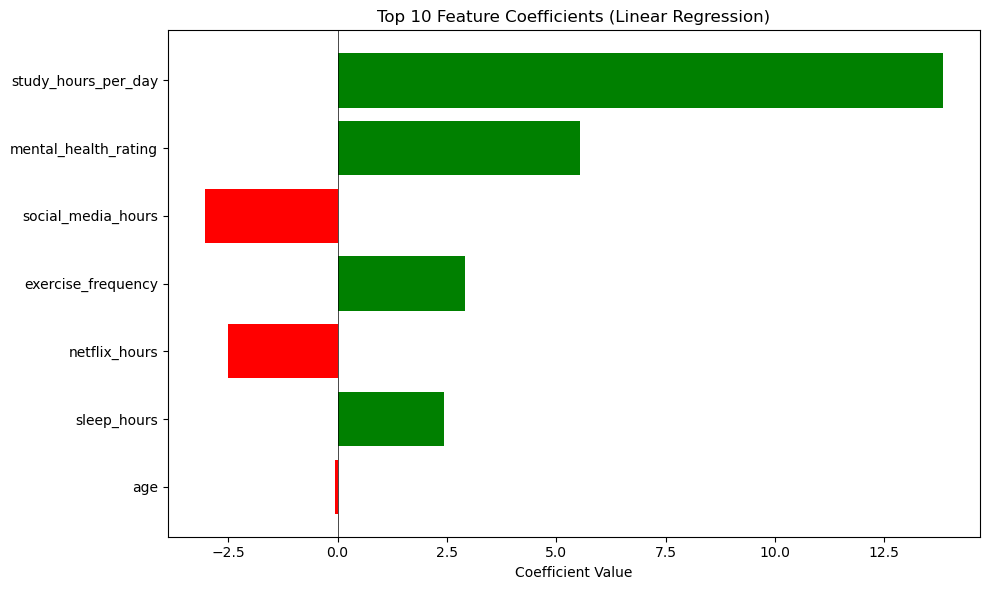


💡 Positive coefficients = higher exam score
💡 Negative coefficients = lower exam score


In [13]:
# Get feature importance from Linear Regression coefficients
preprocessor.fit(X_train)

# Get feature names after preprocessing
encoded_features = []
if len(cat_cols) > 0:
    encoder = preprocessor.named_transformers_['cat'].named_steps['encoder']
    encoded_features = encoder.get_feature_names_out(cat_cols).tolist()

all_features = num_cols + encoded_features

# Get coefficients from Linear Regression
coefficients = lr_pipeline.named_steps['model'].coef_

# Create dataframe and sort by absolute coefficient
coef_df = pd.DataFrame({
    'feature': all_features,
    'coefficient': coefficients,
    'abs_coefficient': np.abs(coefficients)
}).sort_values('abs_coefficient', ascending=False)

print("\nTop 10 most important features (by coefficient magnitude):")
print(coef_df.head(10).to_string(index=False))

# Plot feature importance
plt.figure(figsize=(10, 6))
top_features = coef_df.head(10)
colors = ['green' if c > 0 else 'red' for c in top_features['coefficient']]
plt.barh(top_features['feature'], top_features['coefficient'], color=colors)
plt.xlabel('Coefficient Value')
plt.title('Top 10 Feature Coefficients (Linear Regression)')
plt.axvline(x=0, color='black', linestyle='-', linewidth=0.5)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print("\n💡 Positive coefficients = higher exam score")
print("💡 Negative coefficients = lower exam score")

In [14]:
# Save cleaned data for the web app
data.to_csv("data/student_data_cleaned.csv", index=False)
print("\n✅ Cleaned data saved to data/student_data_cleaned.csv")
print(f"Data shape: {data.shape}")


✅ Cleaned data saved to data/student_data_cleaned.csv
Data shape: (1000, 8)
